# Machine Learning Lab - Learning Unit 7
## Generative Adversarial Networks

Generative adversarial networks (GANs) have been proposed as early as 2014 by [I.J. Goodfellow et al.](https://arxiv.org/pdf/1406.2661.pdf). A GAN consists of two neural networks, the generator and the discriminator. The generator ("the artist") is trained to generate realistically looking images, while the discriminator ("the art critic") learns to separate real and fake images.

The training of a GAN corresponds to a minimax two-player game. The **discriminator** is a classification network with two classes (real/fake) and it is trained to **minimize** the classification error. The **generator** receives random vectors as input and the training objective of the generator is to **maximize** the probability of the discriminator to make a mistake. During training, the generator progressively becomes better at creating images that look real, while the discriminator becomes better at telling apart real and fake images. The process reaches equilibrium when the discriminator can no longer distinguish real images from fakes [[1]](https://www.tensorflow.org/tutorials/generative/dcgan).

We are going to implement a GAN for the generation of blood cell images. The data used is [BloodMNIST](https://medmnist.com/). The dataset consists of 11959 training images, 1712 validation images and 3421 images for testing. Each image shows one cell of one of the following cell types:

*   Basophils
*   Eosinophils
*   Erythroblasts
*   Immature granulocytes
*   Lymphocytes
*   Monocytes
*   Neutrophils
*   Platelets

In the end, the GAN should be usable for generating images of certain cell types, which is why we will implement a conditional GAN (cGAN). Therefore, first find out about cGANs, e.g. [here](https://arxiv.org/pdf/1411.1784.pdf) or [here](https://pub.towardsai.net/a-beginners-guide-to-building-a-conditional-gan-d261e4d94882).

In [18]:
# Install and load the necessary packages, MedMNIST in particular

!pip install medmnist
import medmnist
from medmnist import INFO, Evaluator

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torch.utils.data as data

from torch.autograd import Variable

In [19]:
# Download dataset and prepare loader for training
data_flag = 'bloodmnist'

info = INFO[data_flag]
DataClass = getattr(medmnist, info['python_class'])

img_size = 32
batch_size = 64

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize(img_size)
])

train_dataset = DataClass(split='train',
                          transform=transform,
                          download=True,
                          size=batch_size,
                          mmap_mode='r')

# Set up training data loader
train_loader = data.DataLoader(dataset=train_dataset,
                               batch_size=batch_size,
                               shuffle=True,
                               drop_last=True)
img, label = train_dataset[1]
print('Image size: ', img.shape, 'Label shape: ', label.shape)

Image size:  torch.Size([3, 32, 32]) Label shape:  (1,)


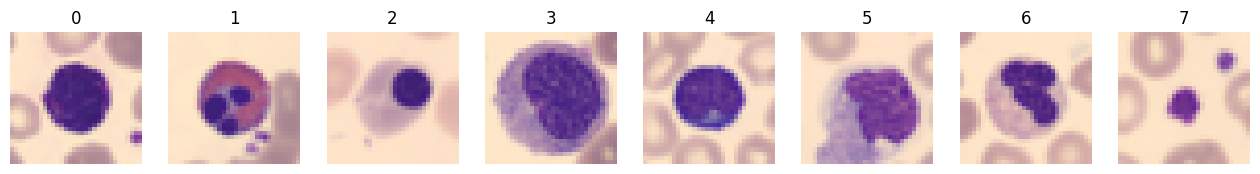

In [20]:
# Plot one image per class
fig, ax = plt.subplots(1, 8, figsize=(16, 4))

for label in range(8):
  plotted = False
  idx = 0
  while not plotted:
    x, y = train_dataset[idx]
    if y.item() == label:
      ax[label].imshow(x.numpy().transpose(1, 2, 0))
      ax[label].title.set_text(y.item())
      ax[label].set_axis_off()
      plotted = True
    idx += 1

## Task 1
Now it's your turn: Implement the generator and the discriminator. Stick to the following architectures:
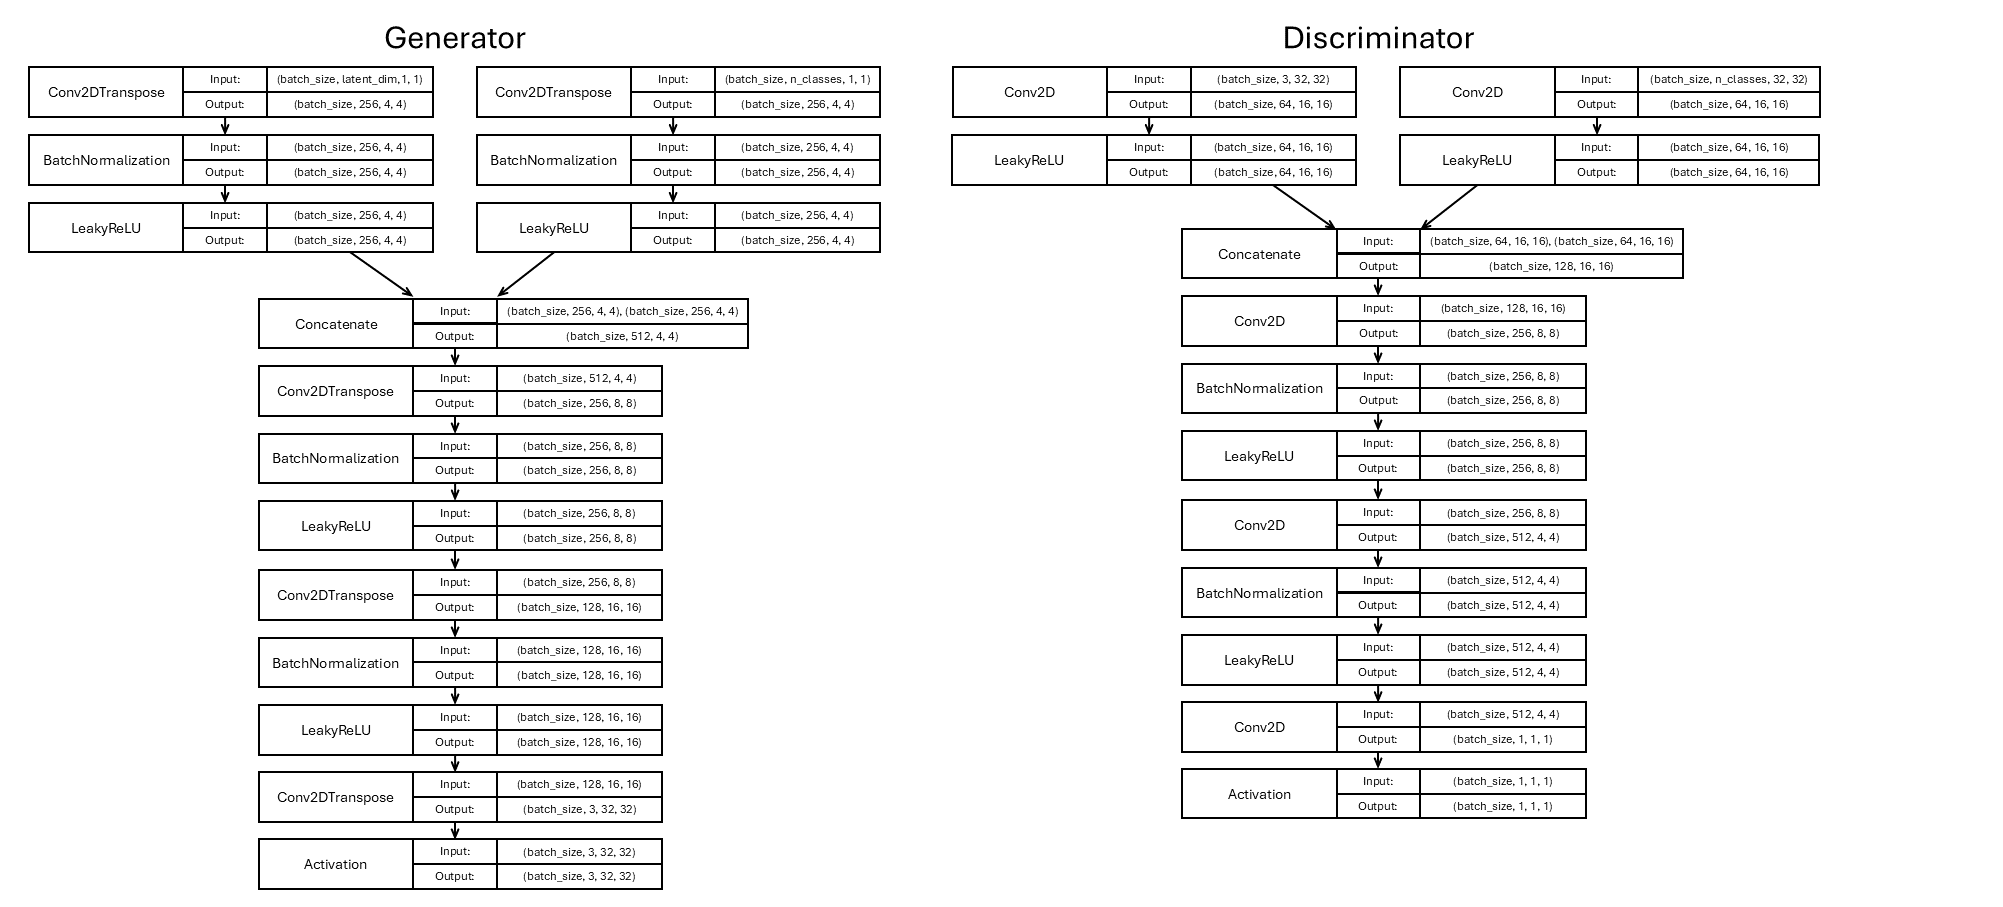

For both networks, use Sigmoid activation. All (transposed) convolutions should use a kernel size of 4 with a stride of 2 and padding=1, except for the ones after the input layers of the generator, which use strides of 1 and no padding.

In [21]:
class Generator(nn.Module):
    def __init__(self, n_classes, n_channels, latent_dim, n_features=256):
        super(Generator, self).__init__()
        self.noise = nn.Sequential(nn.ConvTranspose2d(latent_dim, n_features, kernel_size=4, stride=1, padding=0, bias=False), nn.BatchNorm2d(n_features), nn.LeakyReLU(0.2, inplace=False),)
        self.label = nn.Sequential(nn.ConvTranspose2d(n_classes, n_features, kernel_size=4, stride=1, padding=0, bias=False), nn.BatchNorm2d(n_features), nn.LeakyReLU(0.2, inplace=False),)
        self.main = nn.Sequential(nn.ConvTranspose2d(2 * n_features, n_features, kernel_size=4, stride=2, padding=1, bias=False), nn.BatchNorm2d(n_features), nn.LeakyReLU(0.2, inplace=False),
        nn.ConvTranspose2d(n_features, n_features//2, kernel_size=4, stride=2, padding=1, bias= False), nn.BatchNorm2d(n_features//2), nn.LeakyReLU(0.2, inplace=False),
        nn.ConvTranspose2d(n_features //2, n_channels, kernel_size=4, stride=2, padding=1), nn.Sigmoid(),)

    def forward(self, noise, label):
      z = self.noise(noise)
      y = self.label(label)
      x= torch.cat([z,y], dim=1)
      x= self.main(x)
      return x


class Discriminator(nn.Module):
    def __init__(self, n_classes, n_channels, n_features=64):
        super(Discriminator, self).__init__()
        self.image = nn.Sequential(nn.Conv2d(n_channels, n_features, kernel_size=4, stride=2, padding=1, bias=False), nn.LeakyReLU(0.2, inplace=False),)
        self.label = nn.Sequential(nn.Conv2d(n_classes, n_features, kernel_size=4, stride=2, padding=1, bias=False), nn.LeakyReLU(0.2, inplace=False),)
        self.main = nn.Sequential(nn.Conv2d(2 * n_features, 4 * n_features, kernel_size=4, stride=2, padding=1, bias= False), nn.BatchNorm2d(4 * n_features), nn.LeakyReLU(0.2, inplace=False),
        nn.Conv2d(4 * n_features, 8 * n_features, kernel_size=4, stride=2, padding=1, bias= False), nn.BatchNorm2d(8 * n_features), nn.LeakyReLU(0.2, inplace=False),
        nn.Conv2d( 8 * n_features, 1,kernel_size=4, stride=1, padding=0),
                                  nn.Sigmoid(),)
    def forward(self, image, label):
        x_img = self.image(image)
        x_lbl = self.label(label)
        x = torch.cat([x_img, x_lbl], dim=1)
        x=self.main(x)


        return x

## Task 2

Implement the training loop by filling in the missing code. Use a latent dimension of 50 and the binary cross entropy loss as criterion.

To train the discriminator, use the correct labels real/fake for real/fake images. When training the generator, you want the discriminator to classify the fake images as real...

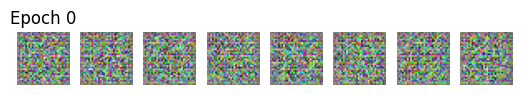

[Epoch 1/50] [D loss: 1.259778] [G loss: 1.962411]
[Epoch 2/50] [D loss: 1.295324] [G loss: 1.167548]
[Epoch 3/50] [D loss: 1.338767] [G loss: 1.032506]
[Epoch 4/50] [D loss: 1.350259] [G loss: 0.990016]
[Epoch 5/50] [D loss: 1.347264] [G loss: 1.004897]


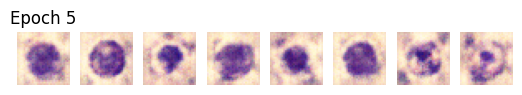

[Epoch 6/50] [D loss: 1.345174] [G loss: 1.015698]
[Epoch 7/50] [D loss: 1.318113] [G loss: 1.087330]
[Epoch 8/50] [D loss: 1.290829] [G loss: 1.158650]
[Epoch 9/50] [D loss: 1.273658] [G loss: 1.261603]
[Epoch 10/50] [D loss: 1.242487] [G loss: 1.362116]


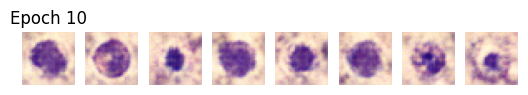

[Epoch 11/50] [D loss: 1.213920] [G loss: 1.443552]
[Epoch 12/50] [D loss: 1.181081] [G loss: 1.489755]
[Epoch 13/50] [D loss: 1.159376] [G loss: 1.525302]
[Epoch 14/50] [D loss: 1.134714] [G loss: 1.581581]
[Epoch 15/50] [D loss: 1.095600] [G loss: 1.643581]


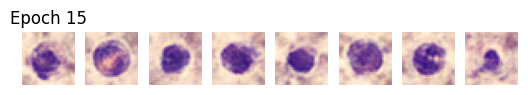

[Epoch 16/50] [D loss: 1.064646] [G loss: 1.696789]
[Epoch 17/50] [D loss: 1.026894] [G loss: 1.792162]
[Epoch 18/50] [D loss: 0.986579] [G loss: 1.855469]
[Epoch 19/50] [D loss: 0.952783] [G loss: 1.998561]
[Epoch 20/50] [D loss: 0.949878] [G loss: 1.923253]


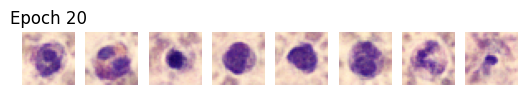

[Epoch 21/50] [D loss: 0.912012] [G loss: 2.043022]
[Epoch 22/50] [D loss: 0.895181] [G loss: 2.096201]
[Epoch 23/50] [D loss: 0.843673] [G loss: 2.202879]
[Epoch 24/50] [D loss: 0.832303] [G loss: 2.253683]
[Epoch 25/50] [D loss: 0.815812] [G loss: 2.254964]


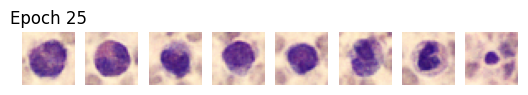

[Epoch 26/50] [D loss: 0.814241] [G loss: 2.204101]
[Epoch 27/50] [D loss: 0.764721] [G loss: 2.367360]
[Epoch 28/50] [D loss: 0.742157] [G loss: 2.510726]
[Epoch 29/50] [D loss: 0.739413] [G loss: 2.534676]
[Epoch 30/50] [D loss: 0.769795] [G loss: 2.401565]


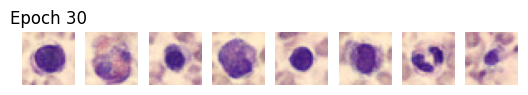

[Epoch 31/50] [D loss: 0.710234] [G loss: 2.621991]
[Epoch 32/50] [D loss: 0.694351] [G loss: 2.698818]
[Epoch 33/50] [D loss: 0.695298] [G loss: 2.662665]
[Epoch 34/50] [D loss: 0.744648] [G loss: 2.596387]
[Epoch 35/50] [D loss: 0.650695] [G loss: 2.672804]


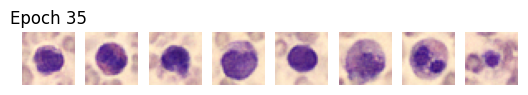

[Epoch 36/50] [D loss: 0.671931] [G loss: 2.911433]
[Epoch 37/50] [D loss: 0.667450] [G loss: 2.833957]
[Epoch 38/50] [D loss: 0.673244] [G loss: 2.714370]
[Epoch 39/50] [D loss: 0.607930] [G loss: 2.933084]
[Epoch 40/50] [D loss: 0.727061] [G loss: 2.719081]


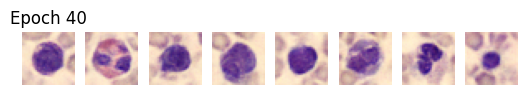

[Epoch 41/50] [D loss: 0.600978] [G loss: 2.878993]
[Epoch 42/50] [D loss: 0.674072] [G loss: 2.795409]
[Epoch 43/50] [D loss: 0.608631] [G loss: 3.101174]
[Epoch 44/50] [D loss: 0.667771] [G loss: 2.905761]
[Epoch 45/50] [D loss: 0.647952] [G loss: 2.971877]


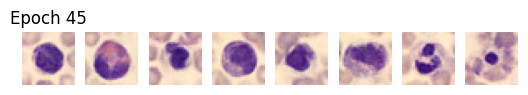

[Epoch 46/50] [D loss: 0.636455] [G loss: 2.780078]
[Epoch 47/50] [D loss: 0.618994] [G loss: 3.019423]
[Epoch 48/50] [D loss: 0.599500] [G loss: 2.978742]
[Epoch 49/50] [D loss: 0.677428] [G loss: 3.019345]
[Epoch 50/50] [D loss: 0.655193] [G loss: 2.862184]


In [22]:
lr = 0.0002
n_epochs = 50
n_classes = 8
latent_dim = 50
n_channels = 3
sample_interval = 5

# Loss function
loss_fn = nn.BCELoss()

# Initialize generator and discriminator
generator = Generator(n_classes, n_channels, latent_dim)
discriminator = Discriminator(n_classes, n_channels)

generator.cuda()
discriminator.cuda()
loss_fn.cuda()

# Optimizers
optimizer_G = torch.optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))

# ----------
#  Training
# ----------
for epoch in range(n_epochs):
  disc_losses = []
  gen_losses = []

  epoch_loss_D = 0
  epoch_loss_G = 0

  # Plot generated images every sample_interval'th epoch
  if epoch % sample_interval == 0:
    with torch.no_grad():
      fig, ax = plt.subplots(1, 8)
      for label in range(8):
        noise = torch.randn(1, latent_dim,1,1).cuda() # (hints see main loop)
        label_input = F.one_hot(torch.tensor([label]), n_classes).float().view(1, n_classes, 1, 1).cuda() # Fixed: view(1, noise) to view(1, n_classes, 1, 1).cuda()
        gen_image = generator(noise, label_input)
        ax[label].imshow(gen_image[0, ...].cpu().detach().numpy().transpose(1, 2, 0))
        ax[label].set_axis_off()
      ax[0].title.set_text('Epoch ' + str(epoch))
      plt.show()

  # Main training loop
  for i, (imgs, labels) in enumerate(train_loader):

    # Transform labels into one hot representation for generator
    # and broadcast to shape [batch_size, n_classes, 1, 1]
    # Additionally change datatype to float and transfer the
    # tensor to GPU
    g_labels = F.one_hot(labels.squeeze(1).long(), n_classes).float().view(batch_size, n_classes, 1,1).cuda()

    # Broadcast labels to correct shape for discriminator
    d_labels = torch.zeros(batch_size, n_classes, img_size, img_size).cuda() + g_labels
    imgs = imgs.cuda()

    # Adversarial ground truths
    y_real = torch.full((batch_size,), 1, dtype=torch.float).cuda()
    y_real_D = torch.full((batch_size,), 0.9, dtype=torch.float).cuda()
    y_fake = torch.full((batch_size,), 0 , dtype=torch.float).cuda() # Fixed: batch_Size to batch_size

    # ---------------------
    #  Train Discriminator
    # ---------------------
    discriminator.zero_grad()

    # Get the loss on real images --> pass real images and d_labels through
    # discriminator --> calculate loss between discriminator predictions
    # and label real (y_real)
    D_out_real = discriminator(imgs, d_labels).squeeze()
    D_loss_real = loss_fn(D_out_real, y_real_D)

    # Get the loss on fake images --> generate fake images by passing noise
    # vector and g_labels through generator
    # --> Pass fake images and d_labels through discriminator
    # --> calculate loss between discriminator predictions and label fake
    noise = torch.randn(batch_size, latent_dim, 1,1).cuda()
    gen_image = generator(noise, g_labels)
    D_out_fake = discriminator(gen_image.detach(), d_labels).squeeze()
    D_loss_fake = loss_fn(D_out_fake, y_fake)

    # Sum up losses and backprop
    D_loss = D_loss_real + D_loss_fake
    D_loss.backward()
    optimizer_D.step()

    disc_losses.append(D_loss.item())
    epoch_loss_D += D_loss.item()

    # -----------------
    #  Train Generator
    # -----------------
    generator.zero_grad()

    # Fool the discriminator --> generate fake images
    # --> Pass fake images through discriminator
    # --> Calculate loss between discriminator predictions and label ???
    noise = torch.randn(batch_size, latent_dim, 1,1).cuda()
    gen_image = generator(noise, g_labels)
    D_out_gen = discriminator(gen_image, d_labels).squeeze()
    gen_loss = loss_fn(D_out_gen, y_real)

    #backprop
    gen_loss.backward()
    optimizer_G.step()

    gen_losses.append(gen_loss.item())
    epoch_loss_G += gen_loss.item()

  print(
      "[Epoch %d/%d] [D loss: %f] [G loss: %f]"
      % (epoch+1, n_epochs, epoch_loss_D/len(disc_losses), epoch_loss_G/len(gen_losses))
  )

 ## Task 3
 Now use your GAN to visualize some fake images for each cell type.

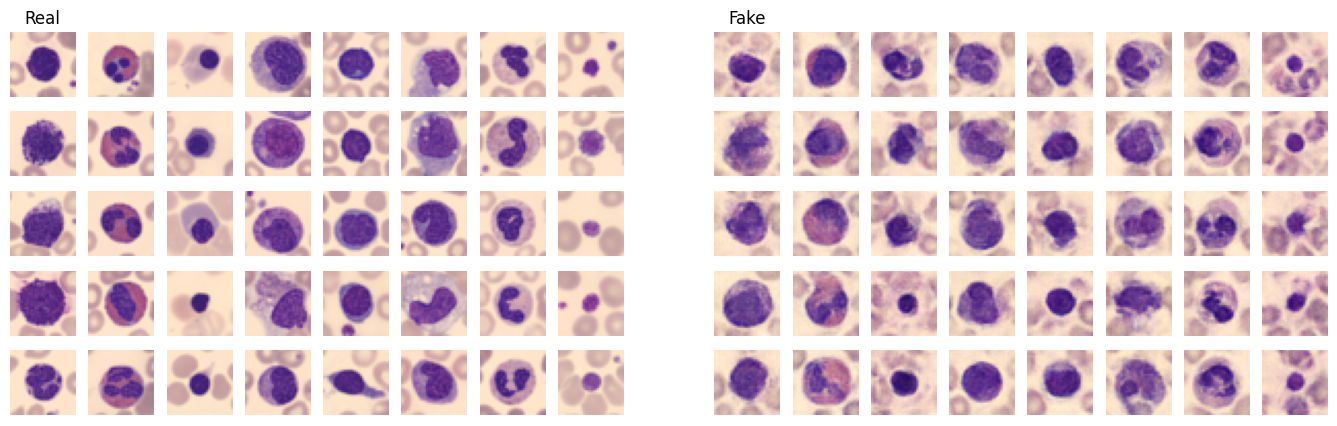

In [23]:
fig, ax = plt.subplots(5, 17, figsize=(17,5))

# Plot real images
for label in range(8):
  plotted = 0
  idx = 0
  while plotted < 5:
    x, y = train_dataset[idx]
    if y.item() == label:
      ax[plotted, label].imshow(x.numpy().transpose(1, 2, 0))
      plotted += 1
    idx += 1

# Generate and plot fake images
for row in range(5):
  for label in range(8):
    noise = torch.randn(1, latent_dim, 1,1).cuda()
    label_input = F.one_hot(torch.tensor([label]), n_classes).float().view(1, n_classes, 1, 1).cuda()

    gen_image = generator(noise, label_input)

    ax[row, label + 9].imshow(gen_image[0, ...].cpu().detach().numpy().transpose(1, 2, 0))
[axi.set_axis_off() for axi in ax.ravel()]
ax[0, 0].title.set_text('Real')
ax[0, 9].title.set_text('Fake')
plt.show()

Since there is no objective loss function used when training generative models, these must be evaluated using the quality of the generated synthetic images. One of the most basic and useful ways to evaluate your GAN is by manually inspecting and judging the generated examples from different iteration steps; see [blog post](https://towardsdatascience.com/on-the-evaluation-of-generative-adversarial-networks-b056ddcdfd3a). For our CNN, visually, the generated images look quite similar to the real ones.

But of course, the manual inspection has many drawbacks:

*   It is subjective and includes the biases of the reviewer.
*   It requires domain knowledge to tell what is realistic and what is not.
*   It is limited in terms of the number of images that can be reviewed.

When measuring how well a GAN performs quantitatively, we need to evaluate two main properties:

1.   Fidelity = the quality of the generated samples. Measures how realistic the
images are. You can think of it as how different each fake sample is from its nearest real sample.
2.   Diversity = the variety of the generated samples. Measures how well the generated images cover the whole diversity or variety of the real distribution.

By capturing fidelity and diversity, you can get a pretty good notion of how well your generator is generating fake images. However, there is another dimension that we need to evaluate in order to assess our generative model.

3.    Authenticity/Generalizability: It measures the rate at which the model invents new samples and tries to spot overfitting to the real data. [Alaa et al.](https://arxiv.org/abs/2102.08921) define it as the fraction of generated samples that are closer to the training data set than other training data points.

Finally, synthetic data should be just as useful as real data for the subsequent task when used for the same predictive purposes.

4.    Predictive performance: We train on synthetic data and test on real data. This evaluates how well the synthetic data covers the distribution of the real data.

## Task 4

We will focus on the last point. **Implement a classification network to predict the cell type of the image input. Train it on generated images only and test its performance on real (test) images of the BloodMNIST dataset.** You can use the same network as in Exercise/Section 1. Just make sure to change the number of input channels and the linear layers at the end of the network. Here, the first linear layer should output 16 features and the second one 8 features corresponding to the eight classes.

In [24]:
class Classification_CNN(nn.Module):
  def __init__(self, in_channels=3, n_classes=8):
    super(Classification_CNN, self).__init__()
    self.features = nn.Sequential(nn.Conv2d(in_channels, 16, kernel_size=3), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2,2),
    nn.Conv2d(16, 16, kernel_size=3), nn.BatchNorm2d(16), nn.ReLU(), nn.Conv2d(16, 64, kernel_size=3), nn.BatchNorm2d(64), nn.ReLU(),
    nn.Conv2d(64, 64, kernel_size=3), nn.BatchNorm2d(64), nn.ReLU(), nn.Conv2d(64, 64,kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2,2),)
    self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 *4 *4, 16), nn.ReLU(), nn.Linear(16, n_classes),)
  def forward(self, x):
    return self.classifier(self.features(x))
classification_mdl = Classification_CNN().cuda()
optimizer = torch.optim.Adam(classification_mdl.parameters())
criterion = nn.CrossEntropyLoss()

steps = 20
batch_size = 64
n_epochs = 50

train_loss = torch.zeros(n_epochs)
train_acc = torch.zeros(n_epochs)

classification_mdl.train()

generator.eval()

for epoch in range(n_epochs):

    for step in range(steps):
      noise = torch.randn(batch_size, latent_dim, 1,1).cuda()
      labels = torch.tensor(np.random.randint(0, 8, batch_size)).cuda()
      g_labels = F.one_hot(labels, n_classes).float().view(batch_size, n_classes,1,1)

      with torch.no_grad():
        gen_image = generator(noise, g_labels)
      # Pass generated image through classification network,
      # Calculate loss between predicted and real class labels
      logits = classification_mdl(gen_image)
      loss = criterion(logits, labels)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      train_loss[epoch] += loss.detach().cpu()
      train_acc[epoch] += torch.sum(torch.argmax(logits, dim=1) == labels).cpu()

train_loss /= steps
train_acc /= (steps*batch_size)

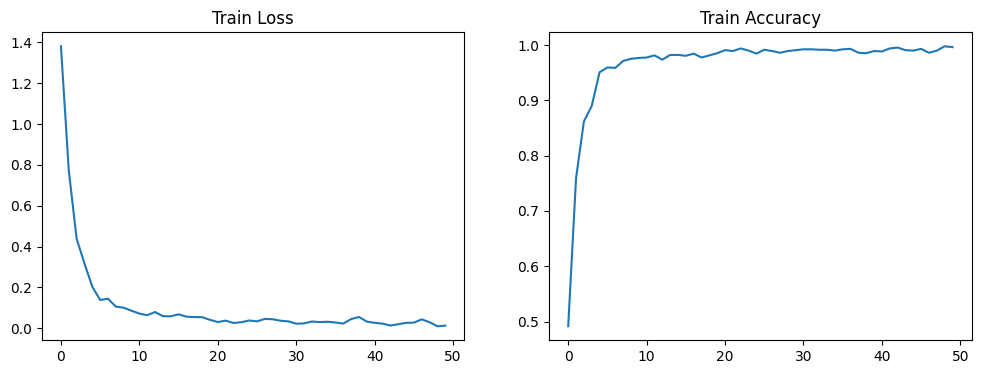

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(train_loss)
ax[0].title.set_text('Train Loss')
ax[1].plot(train_acc)
ax[1].title.set_text('Train Accuracy');

Test accuracy: 0.8243


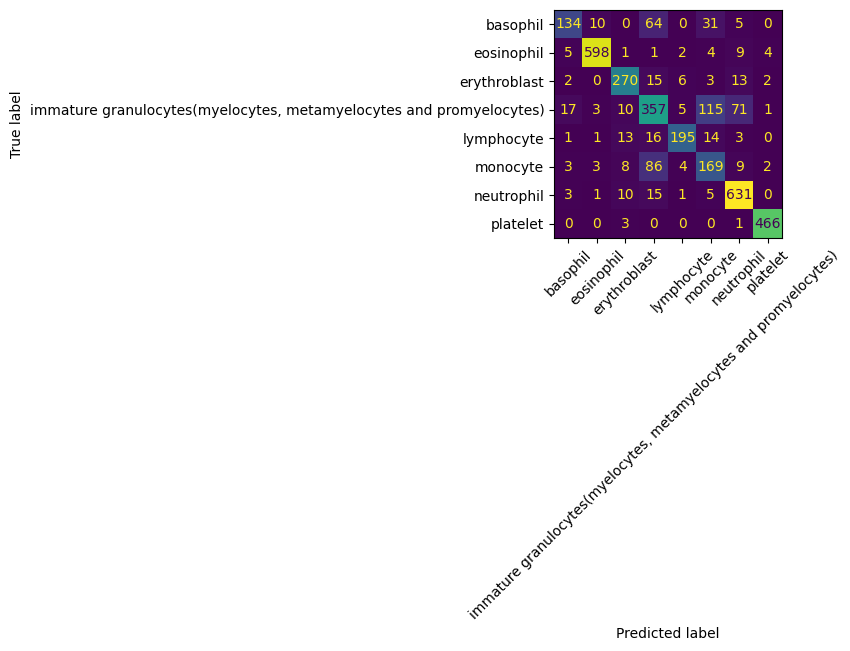

In [26]:

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
test_dataset = DataClass(split='test', transform=transform, download=True, size=64, mmap_mode='r')
test_loader= data.DataLoader(test_dataset, batch_size=128, shuffle=False)
classification_mdl.eval()
y_true=[]
y_pred=[]
with torch.no_grad():
  for imgs, labels in test_loader:
    logits = classification_mdl(imgs.cuda())
    y_pred.append(torch.argmax(logits, dim=1).cpu())
    y_true.append(labels.squeeze(1).cpu())
y_true = torch.cat(y_true).numpy()
y_pred = torch.cat(y_pred).numpy()
print('Test accuracy: %.4f' % accuracy_score(y_true, y_pred))
class_names = [info['label'][str(i)] for i in range(8)]
cm = confusion_matrix(y_true, y_pred, labels=list(range(8)))
fig, ax = plt.subplots(figsize=(8,8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45,colorbar=False)
plt.tight_layout()
plt.show()

GAN training is a tricky thing to do: If the discriminator works too well, any changes the optimizer can make to the generator in one training step won't have a significant effect on the labels assigned by the discriminator. This causes the gradient of the generator to shrink and eventually vanish, preventing it from being trained further. On the other hand, if the generator pulls too far ahead, the easiest strategy for the discriminator that still improves its score will be to assign 0.5 to all inputs it receives - real or generated. Again, this prevents the generator from being trained further. For successful training, the network needs to be tuned to maintain an equilibrium between the two fail states [[2]](https://www.reddit.com/r/learnmachinelearning/comments/17cma9u/some_things_i_learned_about_gan_training/?rdt=45978).

A frequently used variant of GANs is the Wasserstein GAN (WGAN), which helps to avoid these pitfalls. We recommend this [blog post](https://machinelearningmastery.com/how-to-implement-wasserstein-loss-for-generative-adversarial-networks/) for further reading. Here it is described how the Wasserstein loss stabilizes training and the changes that need to be made to the training routine to implement a WGAN.




## Summary

Conditional GAN trained on BloodMNIST for 50 epochs with BCE loss and Adam, latent dimension 50 and batch size 64. One sided label smoothing is used to prevent overfitiing. The disciminators target is 0.9 and the generator is 1.0.

# Training



*   The images quality improve by about 10 epochs. Cell shape, nucleus staining and background color are more refined.
*   At epoch 50, D loss is about 0.66 and G loss about 2.86. In the first run without smoothing, D loss feel to about 0.2 while G loss rose to about 3.9, i.e the discriminator was overpowering the generator.

CNN trained only on generated images reaches about 99.7 percent accuracy and 82.43 percent accuracy on 3,421 real test images. In the forst without label smoothing the real-image accuracy was only 63.7 percent. Here is the holistic overvoew of results.

| Cell type | Test images | Correct | Recall |
|---|---|---|---|
| Basophil | 244 | 134 | 54.9% |
| Eosinophil | 624 | 598 | 95.8% |
| Erythroblast | 311 | 270 | 86.8% |
| Immature granulocytes | 579 | 357 | 61.7% |
| Lymphocyte | 243 | 195 | 80.2% |
| Monocyte | 284 | 169 | 59.5% |
| Neutrophil | 666 | 631 | 94.7% |
| Platelet | 470 | 466 | 99.1% |
